# Iris classification: train, evaluate, and save a model

## Goal
Classify an Iris flower as **setosa**, **versicolor**, or **virginica** from four
measurements in centimeters. Compare five classifiers, evaluate the winner on
unseen test data, save its fitted preprocessing and classifier in BentoML, and check a prediction.

Run the cells in order using this project's Python environment (`uv sync` at the
repository root). The built-in scikit-learn dataset needs no download.
The saved model is a teaching example; one small test split is not evidence
of performance on new field data.

## Setup
The notebook uses a fixed seed, an 80/20 stratified split, and five-fold
cross-validation on the training data only. Scaling stays inside each pipeline
to prevent leakage between folds. The held-out test set never selects the model.

A local `.bentoml/` folder stores training artifacts so this example is isolated
from other models. 

## Results from this run
The support vector machine ranked first in training cross-validation. On the
held-out test set it classified **29 of 30 flowers correctly (96.7% accuracy)**.
The single error was a versicolor predicted as virginica. Reloaded-model predictions matched all 30 test predictions.


In [15]:
import os
from pathlib import Path

# Support launching Jupyter from this folder or the repository root.
PROJECT_DIR = Path.cwd()
if (PROJECT_DIR / "iris" / "iris_model.ipynb").exists():
    PROJECT_DIR = PROJECT_DIR / "iris"
if not (PROJECT_DIR / "iris_model.ipynb").exists():
    raise FileNotFoundError("Launch Jupyter from the iris folder or repository root.")

# Configure BentoML before importing it. This store belongs to this example.
os.environ["BENTOML_HOME"] = str(PROJECT_DIR / ".bentoml")

import bentoml
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import BaseEstimator
from sklearn.datasets import load_iris
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"font.size": 11, "figure.dpi": 100})
print(f"scikit-learn {sklearn.__version__} | BentoML {bentoml.__version__}")

scikit-learn 1.9.1 | BentoML 1.4.39


## 1. Load the data
Each row describes one flower. The four numeric features are sepal length,
sepal width, petal length, and petal width, all in centimeters. Integer labels
0, 1, and 2 map to the species names stored with the dataset.

In [16]:
iris = load_iris(as_frame=True)
features = list(iris.feature_names)
target_names = list(iris.target_names)

data = iris.frame.copy()
data["species"] = data["target"].map(dict(enumerate(target_names)))

print(f"Rows: {data.shape[0]} | Columns: {data.shape[1]}")
display(data.head())

Rows: 150 | Columns: 6


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 2. Inspect the data
Check missing values, feature ranges, and class counts before training.
The `species` column is for interpretation only; it is excluded from the inputs.

In [17]:
data.info()

print("\nMissing values by column:")
display(data.isna().sum().to_frame("missing_values"))

print("Summary statistics:")
display(data[features].describe().T)

print("Class distribution:")
display(data["species"].value_counts().rename_axis("species").to_frame("count"))

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB

Missing values by column:


,missing_values
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
target,0
species,0


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


Class distribution:


,count
species,
setosa,50
versicolor,50
virginica,50


### Measurement distributions

Check the range of each input; histogram counts describe the full example dataset.

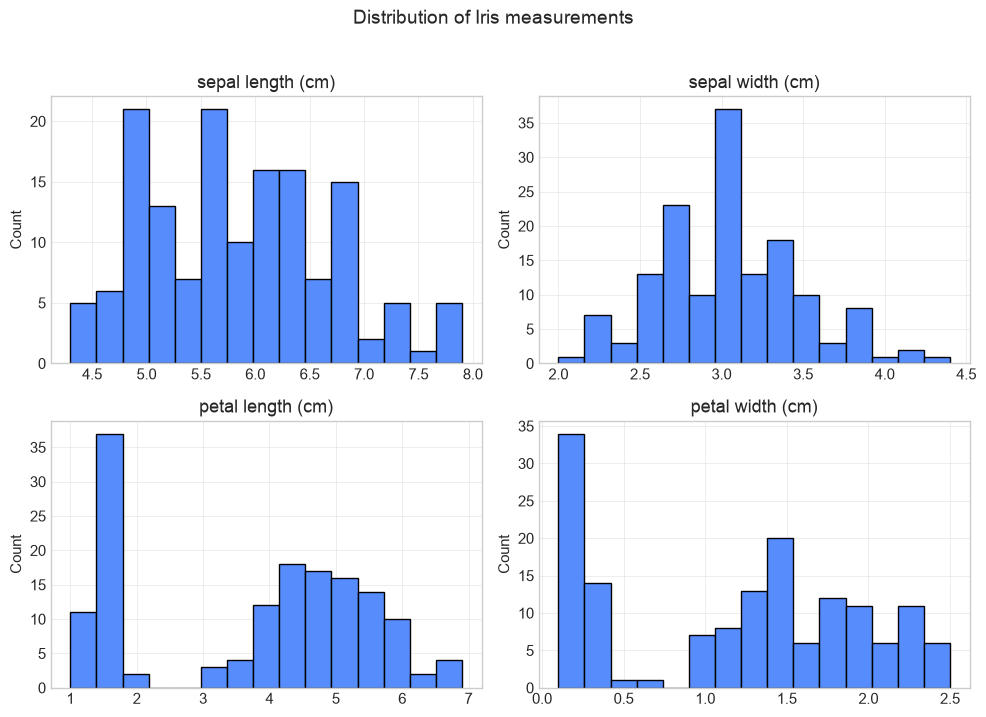

In [18]:
axes = data[features].hist(figsize=(10, 7), bins=15, edgecolor="black")
for axis in axes.ravel():
    axis.set_ylabel("Count")
plt.suptitle("Distribution of Iris measurements", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

### Relationships between measurements

Colors distinguish the species: blue is setosa, orange is versicolor, green is virginica. Each axis retains its measurement name and unit.

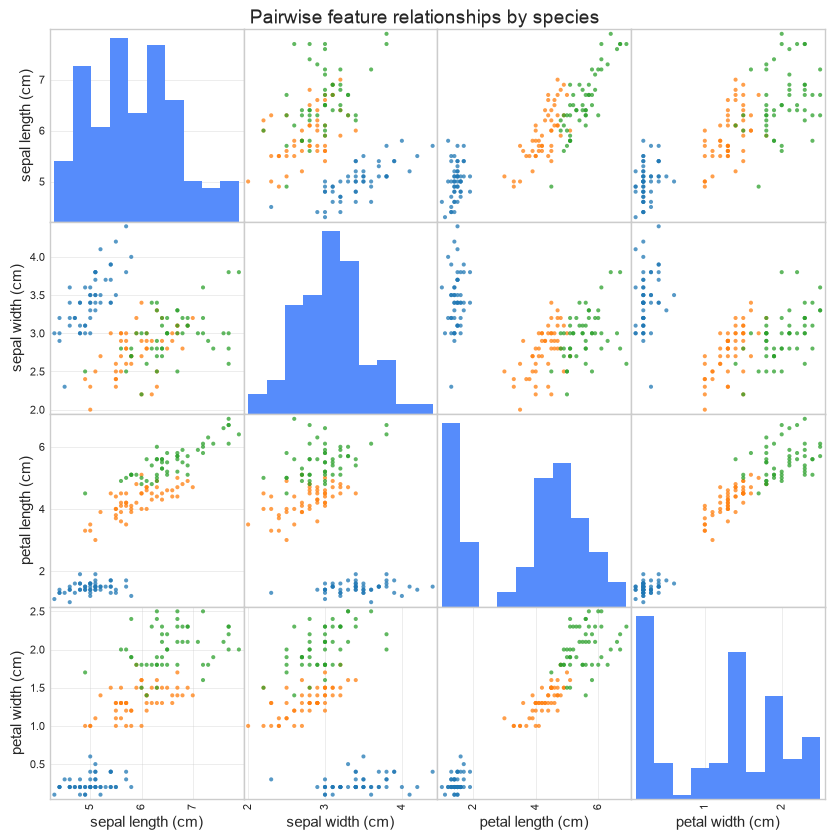

In [19]:
species_colors = data["target"].map({0: "tab:blue", 1: "tab:orange", 2: "tab:green"})
pd.plotting.scatter_matrix(
    data[features],
    figsize=(10, 10),
    diagonal="hist",
    c=species_colors,
    alpha=0.75,
    s=35,
)
plt.suptitle("Pairwise feature relationships by species", y=0.9, fontsize=14)
plt.show()

## 3. Reserve an independent test set
Stratification preserves class proportions. Keep the test features and labels
aside until the winning classifier has been selected using training data.

In [20]:
X = data[features]
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")

Training samples: 120
Test samples: 30


## 4. Compare five classifiers
Logistic regression, nearest neighbors, and the support vector machine use
standardized features. Trees do not require scaling. Every candidate receives
the same folds. Rank by mean validation accuracy, then macro F1 to break ties.
The fold standard deviation measures variation across folds, not a confidence interval.

In [21]:
def build_candidate_models(random_state: int) -> dict[str, BaseEstimator]:
    """Create the classification algorithms used in the comparison.

    Args:
        random_state: Seed used by algorithms with stochastic behavior.

    Returns:
        Mapping from readable model names to unfitted estimators.
    """
    return {
        "Logistic Regression": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1_000, random_state=random_state),
        ),
        "K-Nearest Neighbors": make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=5),
        ),
        "Support Vector Machine": make_pipeline(
            StandardScaler(),
            SVC(kernel="rbf", C=1.0, gamma="scale"),
        ),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=4,
            random_state=random_state,
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=200,
            random_state=random_state,
            n_jobs=1,
        ),
    }


def compare_models(
    models: dict[str, BaseEstimator],
    X_train: pd.DataFrame,
    y_train: pd.Series,
    cross_validator: StratifiedKFold,
) -> pd.DataFrame:
    """Evaluate candidate estimators with identical cross-validation folds.

    Args:
        models: Named, unfitted classification estimators.
        X_train: Training features with one observation per row.
        y_train: Integer class labels aligned with ``X_train``.
        cross_validator: Stratified fold generator shared by all candidates.

    Returns:
        Results sorted by descending mean cross-validation accuracy.
    """
    rows: list[dict[str, float | str]] = []

    for name, model in models.items():
        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=cross_validator,
            scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
            n_jobs=1,
        )
        rows.append(
            {
                "Model": name,
                "Mean CV accuracy": scores["test_accuracy"].mean(),
                "Accuracy std": scores["test_accuracy"].std(),
                "Mean CV macro F1": scores["test_f1_macro"].mean(),
            }
        )

    return (
        pd.DataFrame(rows)
        .sort_values(["Mean CV accuracy", "Mean CV macro F1"], ascending=False)
        .reset_index(drop=True)
    )

### Run cross-validation

Only training rows enter this comparison. Larger accuracy and macro F1 are better.

In [22]:
models = build_candidate_models(RANDOM_STATE)
cross_validator = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE,
)
comparison = compare_models(models, X_train, y_train, cross_validator)

display(
    comparison.style.format(
        {
            "Mean CV accuracy": "{:.3f}",
            "Accuracy std": "{:.3f}",
            "Mean CV macro F1": "{:.3f}",
        }
    )
)

,Model,Mean CV accuracy,Accuracy std,Mean CV macro F1
0,Support Vector Machine,0.967,0.017,0.967
1,Logistic Regression,0.958,0.026,0.958
2,K-Nearest Neighbors,0.958,0.026,0.958
3,Random Forest,0.950,0.031,0.949
4,Decision Tree,0.942,0.020,0.941


### Compare validation scores

The bars start at zero. Error bars show one standard deviation across the five folds.

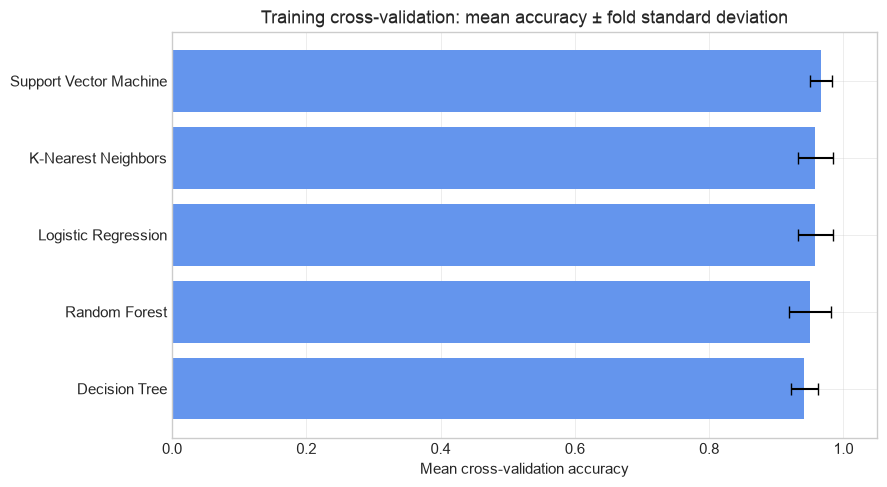

In [23]:
plot_data = comparison.sort_values("Mean CV accuracy")
fig, axis = plt.subplots(figsize=(9, 5))
axis.barh(
    plot_data["Model"],
    plot_data["Mean CV accuracy"],
    xerr=plot_data["Accuracy std"],
    color="cornflowerblue",
    capsize=4,
)
axis.set_xlim(0.0, 1.05)
axis.set_xlabel("Mean cross-validation accuracy")
axis.set_title("Training cross-validation: mean accuracy ± fold standard deviation")
plt.tight_layout()
plt.show()

## 5. Evaluate the selected model
Fit the winner on the 120 training observations, then evaluate once on the
30 held-out flowers. The report shows precision, recall, and F1 per species.
The confusion matrix shows which species are confused. The exported estimator
is this same evaluated pipeline; it is not refitted on the test set.

In [24]:
model_name = str(comparison.loc[0, "Model"])
model = models[model_name]
model.fit(X_train, y_train)
test_predictions = model.predict(X_test)
test_accuracy = accuracy_score(y_test, test_predictions)

print(f"Selected model: {model_name}")
print(f"Held-out test accuracy: {test_accuracy:.3f}")

report = classification_report(
    y_test,
    test_predictions,
    target_names=target_names,
    output_dict=True,
)
display(pd.DataFrame(report).T.round(3))

Selected model: Support Vector Machine
Held-out test accuracy: 0.967


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,10.000
versicolor,1.000,0.900,0.947,10.000
virginica,0.909,1.000,0.952,10.000
accuracy,0.967,0.967,0.967,0.967
macro avg,0.970,0.967,0.967,30.000
weighted avg,0.970,0.967,0.967,30.000


### Inspect classification errors

Rows are true species and columns are predicted species; diagonal cells are correct predictions.

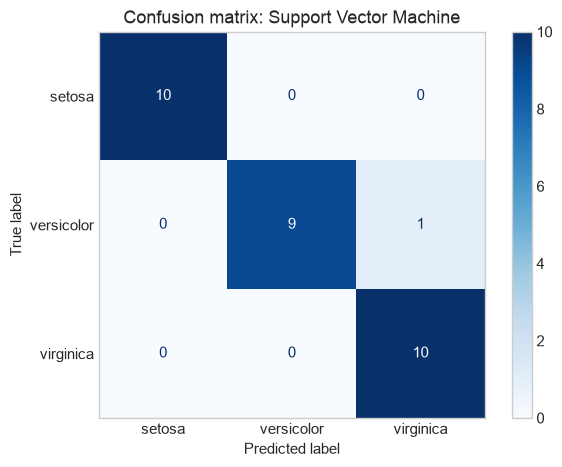

In [25]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=target_names,
    cmap="Blues",
)
plt.title(f"Confusion matrix: {model_name}")
plt.grid(False)
plt.tight_layout()
plt.show()

## 6. Save the fitted pipeline
BentoML stores both preprocessing and classification together. Save the exact
feature order and class-name mapping as metadata so inference can reconstruct
the training schema. Reload and check every held-out prediction before packaging.
The saved-model tag includes a generated version.

In [26]:
bento_model = bentoml.sklearn.save_model(
    "iris_classifier",
    model,
    metadata={
        "feature_names": features,
        "target_names": target_names,
        "selected_algorithm": model_name,
        "test_accuracy": float(test_accuracy),
        "random_state": RANDOM_STATE,
    },
)

loaded_model = bentoml.sklearn.load_model(bento_model.tag)
assert (loaded_model.predict(X_test) == test_predictions).all()
print(f"Saved and reloaded: {bento_model.tag}")

Saved and reloaded: iris_classifier:efmekuwsp2gtnzoc


## 7. Check one prediction
Use the same four columns in their training order. This example's expected
species is setosa.

In [27]:
example_measurement = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=features,
)
predicted_class = int(loaded_model.predict(example_measurement)[0])
print(f"Predicted species: {target_names[predicted_class]}")

Predicted species: setosa
